# 02 — Do text embeddings reduce variance? Monte Carlo results

**Setup recap** (details in `notes/benchmark-protocol.md` and notebook 01):
- **Population:** New England non-profits, N = 20,626.
- **Frame:** TY2022 register (NTEE, state, BMF codes, lagged revenue / expenses / assets / employees, mission and program text).
- **Survey targets:** TY2023 values.
- **Design:** production-style stratified design, NTEE10 × 3 size classes plus a take-all stratum of the 206 largest units. Compromise Neyman allocation, n = 1,000.
- **Replicates:** R independent samples. Every estimator sees the same samples (common random numbers), so comparisons between estimators are precise.

**How to read relative efficiency (RE).** RE = MSE(comparator) / MSE(estimator). Two rules of thumb:
- With RE = 1.25, the estimator achieves the comparator's precision with about 20% fewer take-some sample units.
- A CV shrinks only by 1 − 1/√RE, i.e. by 11% at RE = 1.25.

Every RE carries a 95% Monte Carlo interval (paired-replicate delta method).

In [1]:
import os, sys, json, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
PROJ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(PROJ, "src"))
DATA = os.environ.get("EMBAUX_DATA", "/tmp/claude-0/data")
TAG = os.environ.get("EMBAUX_MC_TAG", "v1_n1000")
import plotstyle; plotstyle.use()
from report import (Y_LABEL, Y_TYPE, family, emb_of, best_conventional, re_vs, cv_band, dotplot, fmt_re)
from mc import metrics
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

df = pd.read_parquet(f"{DATA}/results/mc_ne_{TAG}.parquet")
meta = json.load(open(f"{DATA}/results/mc_ne_{TAG}.json"))
truth = meta["truth"]; R = meta["R"]; n = meta["n"]
YS = [y for y in Y_LABEL if y in truth]
print(f"R = {R} replicates, n = {n}, estimators = {df.estimator.nunique()}, targets = {len(YS)}")
m = metrics(df, truth, baseline="GREG_size_cat")
m["family"] = m.estimator.map(family); m["y_type"] = m.y.map(Y_TYPE)

R = 500 replicates, n = 1000, estimators = 40, targets = 14


## 1. Stage 1: what the population says is possible (anticipated-variance ceilings)
Each auxiliary set is fitted on the whole population (optimistic). The ratio AV(strong frame) / AV(frame + text) is
the most a model-assisted estimator could gain at this design. Monte Carlo gains far above these ceilings would mean
leakage; gains far below would mean overfitting.

In [2]:
dg = pd.read_csv(f"{DATA}/results/diag_ne_n{n}.csv")
keep = ["weak", "strong+lsa256_mission:pc32_ratio", "strong+lsa256_full:pc32_ratio", "strong+minilm_mission:pc32_ratio",
        "strong+minilm_full:pc32_ratio", "strong+PERMUTED_minilm_full:pc32_ratio", "strong+ORACLE_lagged_survey_vars"]
ceil = dg[dg.features.isin(keep)].pivot(index="y", columns="features", values="re_vs_baseline")[keep]
ceil.index = [Y_LABEL.get(i, i) for i in ceil.index]
display(ceil.round(2))

features,weak,strong+lsa256_mission:pc32_ratio,strong+lsa256_full:pc32_ratio,strong+minilm_mission:pc32_ratio,strong+minilm_full:pc32_ratio,strong+PERMUTED_minilm_full:pc32_ratio,strong+ORACLE_lagged_survey_vars
y_bin_foreign_activities,0.99,1.01,1.03,1.04,1.06,1.00,1.00
Share granting to individuals,1.00,1.08,1.17,1.06,1.10,1.00,1.00
Share with gov. grants,0.99,1.09,1.14,1.10,1.13,1.00,1.01
Share with volunteers,1.00,1.04,1.06,1.03,1.06,0.99,1.00
Share lobbying,0.99,1.03,1.06,1.03,1.04,0.99,1.01
Contributions,0.98,1.08,1.19,1.03,1.16,0.92,2.33
Employees,0.03,0.96,0.93,1.01,1.02,0.88,1.00
Total expenses,0.14,0.93,0.97,0.99,0.97,0.96,1.00
Fundraising expenses,0.88,1.04,1.20,1.04,1.07,0.92,8.46
Government grants,0.92,1.05,1.13,0.95,1.05,0.89,7.53


## 2. Validity first: are the estimators approximately unbiased, and do their intervals cover?
Text estimators are only interesting if they keep design consistency. The table shows relative bias (% of the
total, with MC SE) and 95% CI coverage for the main estimators. Coverage MC SE ≈ 1 pp at R = 500.

In [3]:
MAIN = ["HT", "GREG_size_cat", "MCAL_frame_ratio", "RIDGE_size_cat+lsa256_full:ratio32", "MCAL_ratio+lsa256_full",
        "MCAL_ratio+minilm_full", "MCAL_ratio+lsa256_full:nocf", "SYN_ratio+lsa256_full"]
main = m[m.estimator.isin(MAIN)]
bias = main.pivot(index="y", columns="estimator", values="rel_bias_pct")[MAIN].reindex(YS)
cov = main.pivot(index="y", columns="estimator", values="coverage_pct")[[e for e in MAIN if not e.startswith("SYN")]].reindex(YS)
bias.index = cov.index = [Y_LABEL[y] for y in YS]
print("Relative bias (%):"); display(bias.round(2))
print("95% CI coverage (%):"); display(cov.round(1))
print("Max |MC SE of relative bias| (pp):", round(main.rel_bias_mcse_pct.max(), 2))

Relative bias (%):


estimator,HT,GREG_size_cat,MCAL_frame_ratio,RIDGE_size_cat+lsa256_full:ratio32,MCAL_ratio+lsa256_full,MCAL_ratio+minilm_full,MCAL_ratio+lsa256_full:nocf,SYN_ratio+lsa256_full
Total expenses,0.07,0.03,0.02,0.03,0.02,0.02,-0.05,-0.08
Total revenue,0.09,0.21,0.38,0.21,0.34,0.42,0.92,2.33
Employees,0.37,-0.02,-0.01,-0.03,-0.01,-0.01,-0.02,-0.67
Salaries,0.17,0.14,0.05,0.35,0.02,0.03,-0.12,-0.14
Government grants,0.80,0.52,0.41,-0.02,0.25,0.33,0.22,0.54
Program service revenue,0.10,0.25,0.22,0.33,0.22,0.22,0.15,0.00
Contributions,0.17,0.30,0.22,0.08,0.11,0.15,-0.47,-0.49
Fundraising expenses,0.13,0.98,0.72,0.82,0.63,0.65,-0.20,-0.68
Officer compensation,0.39,0.19,0.32,0.38,0.27,0.19,0.79,1.06
Volunteers (capped 10k),-0.42,-0.43,-0.38,-0.66,-0.25,-0.15,-0.92,6.42


95% CI coverage (%):


estimator,HT,GREG_size_cat,MCAL_frame_ratio,RIDGE_size_cat+lsa256_full:ratio32,MCAL_ratio+lsa256_full,MCAL_ratio+minilm_full,MCAL_ratio+lsa256_full:nocf
Total expenses,94.6,92.4,91.2,90.8,91.2,90.6,74.2
Total revenue,95.2,89.4,87.6,87.2,88.2,87.0,80.2
Employees,94.6,94.2,94.2,93.0,94.2,94.0,93.8
Salaries,95.6,93.0,92.4,83.2,92.2,92.0,79.8
Government grants,92.2,91.2,90.2,87.8,90.4,90.4,79.6
Program service revenue,95.4,89.4,89.2,86.6,90.6,90.6,78.8
Contributions,92.2,90.4,90.2,87.6,90.4,91.2,81.4
Fundraising expenses,92.8,89.2,89.0,86.6,88.8,89.2,81.8
Officer compensation,92.8,90.8,90.0,90.0,90.0,90.2,81.8
Volunteers (capped 10k),88.0,87.8,89.0,86.6,86.8,87.8,85.2


Max |MC SE of relative bias| (pp): 118.61


## 3. Efficiency: text estimators against the strongest conventional comparator
The comparator for each target is **the best conventional estimator for that target**: the status-quo GREG
family plus text-free machine learning, chosen after the fact by Monte Carlo MSE. This choice favours the
comparator, which makes it conservative for the text claim.

,best conventional comparator,label
y,,
y_bin_grants_to_indiv_us,GREG_ratio,Share granting to individuals
y_bin_has_gov_grants,GREG_size_cat,Share with gov. grants
y_bin_has_volunteers,GREG_size,Share with volunteers
y_bin_lobbying,GREG_ratio,Share lobbying
y_contrib,GREG_sep,Contributions
y_employees,GREG_size,Employees
y_expenses,GREG_size,Total expenses
y_fundraising_exp,GREG_sep,Fundraising expenses
y_gov_grants,GREG_sep,Government grants


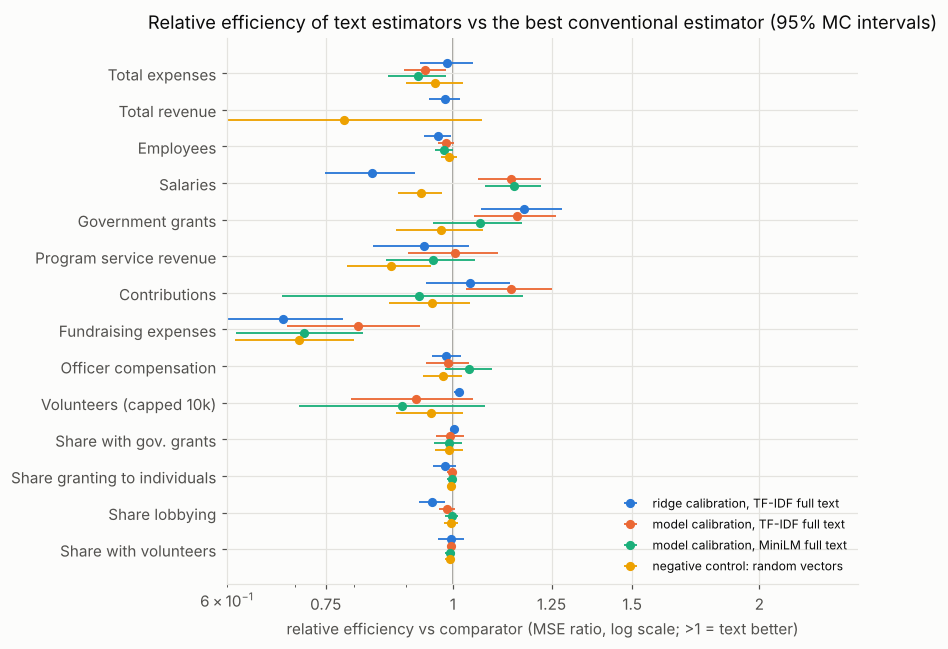

estimator,RIDGE_size_cat+lsa256_full:ratio32,MCAL_ratio+lsa256_full,MCAL_ratio+minilm_full,MCAL_ratio+random384
Total expenses (register-type),0.99 ± 0.06,0.94 ± 0.04,0.92 ± 0.06,0.96 ± 0.06
Total revenue (register-type),0.98 ± 0.03,0.05 ± 0.09,0.02 ± 0.03,0.78 ± 0.29
Employees (register-type),0.97 ± 0.03,0.98 ± 0.02,0.98 ± 0.02,0.99 ± 0.02
Salaries (admin-in-practice),0.83 ± 0.08,1.14 ± 0.08,1.15 ± 0.07,0.93 ± 0.05
Government grants (survey-only),1.17 ± 0.11,1.16 ± 0.11,1.06 ± 0.11,0.97 ± 0.10
Program service revenue (survey-only),0.94 ± 0.10,1.01 ± 0.10,0.95 ± 0.10,0.87 ± 0.08
Contributions (survey-only),1.04 ± 0.10,1.14 ± 0.11,0.93 ± 0.25,0.95 ± 0.09
Fundraising expenses (survey-only),0.68 ± 0.10,0.81 ± 0.12,0.71 ± 0.10,0.71 ± 0.10
Officer compensation (survey-only),0.99 ± 0.03,0.99 ± 0.05,1.04 ± 0.06,0.98 ± 0.04
Volunteers (capped 10k) (survey-only (heavy-tailed)),1.01 ± 0.01,0.92 ± 0.13,0.89 ± 0.18,0.95 ± 0.07


In [4]:
best = best_conventional(m)
display(best.rename("best conventional comparator").to_frame().assign(label=lambda d: d.index.map(Y_LABEL)))
tab = re_vs(df, truth, best.to_dict())
tab["family"] = tab.estimator.map(family)
ESTS = ["RIDGE_size_cat+lsa256_full:ratio32", "MCAL_ratio+lsa256_full", "MCAL_ratio+minilm_full", "MCAL_ratio+random384"]
LAB = {"RIDGE_size_cat+lsa256_full:ratio32": "ridge calibration, TF-IDF full text",
       "MCAL_ratio+lsa256_full": "model calibration, TF-IDF full text",
       "MCAL_ratio+minilm_full": "model calibration, MiniLM full text",
       "MCAL_ratio+random384": "negative control: random vectors"}
fig, ax = plt.subplots(figsize=(8, 6))
dotplot(ax, tab, YS, ESTS, LAB, xlim=(0.6, 2.5))
ax.set_title("Relative efficiency of text estimators vs the best conventional estimator (95% MC intervals)")
plt.tight_layout(); plt.show()
wide = tab[tab.estimator.isin(ESTS)].assign(cell=lambda d: [fmt_re(a, b) for a, b in zip(d.re, d.re_se)])
wide = wide.pivot(index="y", columns="estimator", values="cell")[ESTS].reindex(YS)
wide.index = [f"{Y_LABEL[y]} ({Y_TYPE[y]})" for y in YS]
display(wide)

## 4. Attribution: is it the text, or just a more flexible model?
Same learner, same folds, same design. The only difference is whether text PCs enter the features.

In [5]:
att = re_vs(df, truth, "MCAL_frame_ratio")
att = att[att.estimator.isin(["MCAL_ratio+lsa256_full", "MCAL_ratio+lsa256_mission", "MCAL_ratio+minilm_full",
                              "MCAL_ratio+minilm_mission", "MCAL_ratio+random384", "MCAL_ratio+PERM_lsa256_full"])]
att_w = att.assign(cell=lambda d: [fmt_re(a, b) for a, b in zip(d.re, d.re_se)]).pivot(index="y", columns="estimator", values="cell").reindex(YS)
att_w.index = [Y_LABEL[y] for y in YS]
display(att_w)

estimator,MCAL_ratio+PERM_lsa256_full,MCAL_ratio+lsa256_full,MCAL_ratio+lsa256_mission,MCAL_ratio+minilm_full,MCAL_ratio+minilm_mission,MCAL_ratio+random384
Total expenses,1.04 ± 0.09,1.00 ± 0.08,1.02 ± 0.09,0.99 ± 0.06,1.01 ± 0.08,1.03 ± 0.06
Total revenue,12.62 ± 9.72,1.56 ± 0.06,4.89 ± 1.26,0.55 ± 0.02,0.17 ± 0.01,23.98 ± 36.78
Employees,1.00 ± 0.01,1.00 ± 0.02,1.00 ± 0.01,1.00 ± 0.02,1.00 ± 0.02,1.01 ± 0.01
Salaries,0.98 ± 0.05,1.14 ± 0.08,1.05 ± 0.07,1.15 ± 0.07,1.03 ± 0.07,0.93 ± 0.05
Government grants,0.99 ± 0.05,1.16 ± 0.09,1.05 ± 0.06,1.06 ± 0.08,1.03 ± 0.07,0.97 ± 0.06
Program service revenue,1.00 ± 0.03,1.12 ± 0.06,1.00 ± 0.04,1.06 ± 0.06,0.99 ± 0.04,0.97 ± 0.03
Contributions,0.96 ± 0.04,1.16 ± 0.07,1.04 ± 0.06,0.94 ± 0.24,1.02 ± 0.06,0.97 ± 0.04
Fundraising expenses,0.94 ± 0.04,1.10 ± 0.06,0.99 ± 0.04,0.98 ± 0.05,0.98 ± 0.06,0.96 ± 0.04
Officer compensation,0.98 ± 0.04,1.03 ± 0.04,1.03 ± 0.04,1.08 ± 0.06,1.04 ± 0.04,1.02 ± 0.04
Volunteers (capped 10k),1.01 ± 0.02,0.97 ± 0.07,0.93 ± 0.12,0.94 ± 0.13,0.99 ± 0.05,1.00 ± 0.01


## 5. Embedding ladder and text field
Is a neural embedding better than TF-IDF? Is the richer program text better than the short mission statement?
(Cohere rungs are added when the API becomes reachable; see README.)

In [6]:
lad = tab[tab.estimator.isin(["MCAL_ratio+lsa256_mission", "MCAL_ratio+lsa256_full", "MCAL_ratio+minilm_mission", "MCAL_ratio+minilm_full"])]
lad_w = lad.pivot(index="y", columns="estimator", values="re").reindex(YS).round(2)
lad_w.index = [Y_LABEL[y] for y in YS]
display(lad_w)

estimator,MCAL_ratio+lsa256_full,MCAL_ratio+lsa256_mission,MCAL_ratio+minilm_full,MCAL_ratio+minilm_mission
Total expenses,0.94,0.96,0.92,0.94
Total revenue,0.05,0.16,0.02,0.01
Employees,0.98,0.99,0.98,0.99
Salaries,1.14,1.05,1.15,1.03
Government grants,1.16,1.05,1.06,1.03
Program service revenue,1.01,0.90,0.95,0.89
Contributions,1.14,1.02,0.93,1.00
Fundraising expenses,0.81,0.72,0.71,0.72
Officer compensation,0.99,0.99,1.04,1.00
Volunteers (capped 10k),0.92,0.88,0.89,0.94


## 6. Controls and pitfalls
- **Random and row-permuted embeddings** must not beat the comparator.
- **No cross-fitting** should show overfitting: optimistic variance estimates and under-coverage.
- **The synthetic estimator** Σ m̂ (no design correction) shows model bias.

In [7]:
ctl = m[m.estimator.isin(["MCAL_ratio+random384", "MCAL_ratio+PERM_lsa256_full", "RIDGE_size_cat+random384:ratio32",
                          "MCAL_ratio+lsa256_full:nocf", "SYN_ratio+lsa256_full", "GREG_weak+lsa256_full:add32"])]
for col in ["re", "rel_bias_pct", "coverage_pct", "var_rel_bias_pct"]:
    t = ctl.pivot(index="y", columns="estimator", values=col).reindex(YS); t.index = [Y_LABEL[y] for y in YS]
    print(col, "(re is vs GREG_size_cat)" if col == "re" else ""); display(t.round(2))

re (re is vs GREG_size_cat)


estimator,GREG_weak+lsa256_full:add32,MCAL_ratio+PERM_lsa256_full,MCAL_ratio+lsa256_full:nocf,MCAL_ratio+random384,RIDGE_size_cat+random384:ratio32,SYN_ratio+lsa256_full
Total expenses,0.10,1.01,0.68,1.00,1.01,0.29
Total revenue,0.19,0.42,0.00,0.80,1.01,0.00
Employees,0.02,1.00,0.98,1.01,1.01,0.03
Salaries,0.28,1.26,1.55,1.20,1.02,0.72
Government grants,0.81,1.05,1.27,1.03,1.03,1.35
Program service revenue,0.41,1.03,1.23,0.99,1.00,0.98
Contributions,0.84,1.04,1.28,1.05,1.01,1.07
Fundraising expenses,0.98,1.07,1.46,1.10,0.97,1.35
Officer compensation,0.65,0.94,0.70,0.98,1.00,0.65
Volunteers (capped 10k),0.78,0.96,0.98,0.95,1.00,0.04


rel_bias_pct 


estimator,GREG_weak+lsa256_full:add32,MCAL_ratio+PERM_lsa256_full,MCAL_ratio+lsa256_full:nocf,MCAL_ratio+random384,RIDGE_size_cat+random384:ratio32,SYN_ratio+lsa256_full
Total expenses,0.15,0.02,-0.05,0.03,0.02,-0.08
Total revenue,0.17,0.26,0.92,0.24,0.20,2.33
Employees,0.40,-0.01,-0.02,-0.01,-0.03,-0.67
Salaries,0.21,0.07,-0.12,0.09,0.25,-0.14
Government grants,0.42,0.48,0.22,0.47,0.48,0.54
Program service revenue,0.19,0.22,0.15,0.23,0.21,0.00
Contributions,0.12,0.32,-0.47,0.27,0.33,-0.49
Fundraising expenses,0.20,0.80,-0.20,0.74,1.22,-0.68
Officer compensation,0.65,0.36,0.79,0.30,0.33,1.06
Volunteers (capped 10k),0.37,-0.32,-0.92,-0.31,-0.44,6.42


coverage_pct 


estimator,GREG_weak+lsa256_full:add32,MCAL_ratio+PERM_lsa256_full,MCAL_ratio+lsa256_full:nocf,MCAL_ratio+random384,RIDGE_size_cat+random384:ratio32,SYN_ratio+lsa256_full
Total expenses,91.6,92.0,74.2,91.2,89.6,NaN
Total revenue,93.6,87.4,80.2,88.4,86.8,NaN
Employees,91.2,94.8,93.8,95.2,92.8,NaN
Salaries,88.8,91.4,79.8,90.4,89.2,NaN
Government grants,90.2,91.6,79.6,91.0,88.4,NaN
Program service revenue,92.0,90.4,78.8,89.4,86.8,NaN
Contributions,92.6,90.4,81.4,90.8,88.8,NaN
Fundraising expenses,89.0,88.2,81.8,89.0,86.8,NaN
Officer compensation,89.4,90.2,81.8,90.0,90.8,NaN
Volunteers (capped 10k),86.0,89.0,85.2,88.6,88.0,NaN


var_rel_bias_pct 


estimator,GREG_weak+lsa256_full:add32,MCAL_ratio+PERM_lsa256_full,MCAL_ratio+lsa256_full:nocf,MCAL_ratio+random384,RIDGE_size_cat+random384:ratio32,SYN_ratio+lsa256_full
Total expenses,-24.73,-15.17,-62.49,-16.11,-21.64,NaN
Total revenue,-23.36,-72.60,-99.96,-47.74,-39.05,NaN
Employees,-25.17,-0.87,-3.53,-0.09,-7.86,NaN
Salaries,-29.63,-9.90,-53.20,-14.81,-26.36,NaN
Government grants,-9.83,-11.80,-53.31,-14.07,-27.00,NaN
Program service revenue,-20.21,-17.31,-55.66,-20.33,-30.61,NaN
Contributions,-9.72,-12.80,-49.25,-11.97,-24.48,NaN
Fundraising expenses,-23.60,-33.01,-49.75,-31.65,-39.49,NaN
Officer compensation,-20.81,2.16,-45.94,6.44,1.89,NaN
Volunteers (capped 10k),-24.34,-0.21,-4.55,-1.34,2.63,NaN


## 7. The weak-register scenario: no lagged financial data on the frame
This corresponds to registers without prior-year administrative values (new units, countries without tax linkage).
Here text competes only with industry, state and a coarse size code.

In [8]:
wk = re_vs(df, truth, "GREG_weak")
wk = wk[wk.estimator.isin(["GREG_weak+lsa256_full:add32", "GREG_weak+minilm_full:add32", "GREG_weak+random384:add32", "GREG_size_cat"])]
wk_w = wk.pivot(index="y", columns="estimator", values="re").reindex(YS).round(2); wk_w.index = [Y_LABEL[y] for y in YS]
display(wk_w)

estimator,GREG_size_cat,GREG_weak+lsa256_full:add32,GREG_weak+minilm_full:add32,GREG_weak+random384:add32
Total expenses,8.86,0.88,0.84,0.94
Total revenue,5.07,0.95,0.88,0.92
Employees,36.52,0.78,0.81,0.91
Salaries,2.70,0.76,0.77,0.87
Government grants,1.09,0.88,0.85,0.87
Program service revenue,2.08,0.85,0.80,0.92
Contributions,1.10,0.93,0.88,0.89
Fundraising expenses,0.84,0.83,0.80,0.85
Officer compensation,1.39,0.91,0.86,0.88
Volunteers (capped 10k),1.01,0.78,0.82,0.91


## 8. Real-world translation: CVs, quality bands, and sample-size savings
- **Take-some saving:** σ ≈ 1 − 1/RE, applied to the take-some part of the sample (the take-all units are fixed).
- **Quality letters:** Statistics Canada's commonly used CV bands are A < 5%, B < 10%, C < 15%, D < 25%, E < 35%, F ≥ 35%. Confirm these against the target program's own guideline.
- **The binding target sets the saving.** A multipurpose survey must meet *all* its targets, so the saving is set by the target that gains least, not the one that gains most.

In [9]:
n_ta = 206
tr = []
for y in YS:
    b = best[y]
    cv_b = m[(m.y == y) & (m.estimator == b)].rrmse_pct.iat[0]
    for e in ["MCAL_ratio+lsa256_full", "MCAL_ratio+minilm_full"]:
        r_ = tab[(tab.y == y) & (tab.estimator == e)]
        re_, cv_t = r_.re.iat[0], m[(m.y == y) & (m.estimator == e)].rrmse_pct.iat[0]
        tr.append({"target": Y_LABEL[y], "text estimator": e, "comparator": b, "CV comparator %": cv_b, "band": cv_band(cv_b),
                   "CV text %": cv_t, "band text": cv_band(cv_t), "RE": re_,
                   "take-some sample saving %": 100 * (1 - 1 / re_) if re_ > 1 else 0.0})
trt = pd.DataFrame(tr).round(2); display(trt)
for e in ["MCAL_ratio+lsa256_full", "MCAL_ratio+minilm_full"]:
    sub = trt[trt["text estimator"] == e]
    print(f"{e}: binding (minimum) saving across ALL targets = {sub['take-some sample saving %'].min():.1f}%;"
          f" across survey-only targets = {sub[sub.target.isin([Y_LABEL[y] for y in YS if Y_TYPE[y].startswith('survey-only')])]['take-some sample saving %'].min():.1f}%")

,target,text estimator,comparator,CV comparator %,band,CV text %,band text,RE,take-some sample saving %
0,Total expenses,MCAL_ratio+lsa256_full,GREG_size,0.45,A,0.47,A,0.94,0.00
1,Total expenses,MCAL_ratio+minilm_full,GREG_size,0.45,A,0.47,A,0.92,0.00
2,Total revenue,MCAL_ratio+lsa256_full,GREG_size,0.62,A,2.78,A,0.05,0.00
3,Total revenue,MCAL_ratio+minilm_full,GREG_size,0.62,A,4.67,A,0.02,0.00
4,Employees,MCAL_ratio+lsa256_full,GREG_size,0.54,A,0.55,A,0.98,0.00
5,Employees,MCAL_ratio+minilm_full,GREG_size,0.54,A,0.55,A,0.98,0.00
6,Salaries,MCAL_ratio+lsa256_full,MCAL_frame_ratio,1.22,A,1.15,A,1.14,12.25
7,Salaries,MCAL_ratio+minilm_full,MCAL_frame_ratio,1.22,A,1.14,A,1.15,12.90
8,Government grants,MCAL_ratio+lsa256_full,GREG_sep,8.52,B,7.93,B,1.16,13.52
9,Government grants,MCAL_ratio+minilm_full,GREG_sep,8.52,B,8.27,B,1.06,5.85


MCAL_ratio+lsa256_full: binding (minimum) saving across ALL targets = 0.0%; across survey-only targets = 0.0%
MCAL_ratio+minilm_full: binding (minimum) saving across ALL targets = 0.0%; across survey-only targets = 0.0%
